<a href="https://colab.research.google.com/github/crowell97/ES5201/blob/main/ES5201_Lecture17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Common Midpoint Stacking and Deconvolution — A Companion Notebook

**EARTH 5201 — Introduction to Seismology**

**The Ohio State University**

**Companion notebook to Lecture 17 — Reflection Seismology**

This notebook implements the three main quantitative threads from lecture:

1. **The CMP gather and its hyperbolic moveout** — forward-modeling synthetic seismograms at a range of source–receiver offsets for a single horizontal reflector, and confirming the travel-time curve matches the exact hyperbola (and its small-offset approximation).
2. **NMO correction and stacking** — correcting each trace in the gather back to its zero-offset arrival time, stacking the corrected gather into one composite trace, and verifying the predicted $\sqrt{n}$ improvement in signal-to-noise ratio.
3. **Deconvolution** — convolving a reflectivity series with a "ringy" airgun-like source wavelet, then recovering the reflectivity by frequency-domain deconvolution, and seeing firsthand why naive deconvolution is unstable in the presence of noise, and how water-level regularization fixes it.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pylab as plt

plt.rcParams["figure.figsize"] = (9, 5)
rng = np.random.default_rng(17)

## Part 1 — Forward Modeling a CMP Gather

Consider a single horizontal reflector at depth $h$ beneath a layer of constant velocity $v$. For a source–receiver offset $x$, the two-way travel time follows the exact hyperbola

$$t(x) = \sqrt{t_0^2 + x^2/v^2}, \qquad t_0 = \frac{2h}{v},$$

with the small-offset approximation $t(x) \approx t_0\left[1 + \tfrac{1}{2}(x/vt_0)^2\right]$ used throughout lecture. We first build a synthetic CMP gather: one trace per offset, each containing a single Ricker wavelet arriving at the exact travel time for that offset.

t0 = 1.250 s


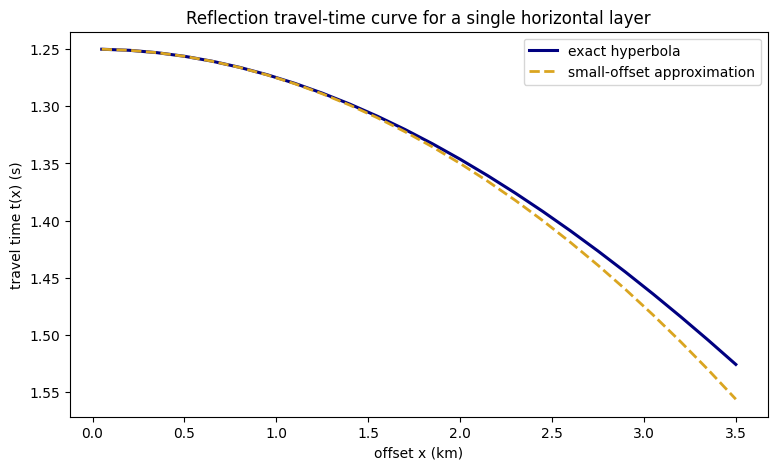

Max |approx - exact| over this offset range: 0.030430548033287153 s


In [2]:
def ricker(t, f=25.0):
    """Zero-phase Ricker (Mexican-hat) wavelet of dominant frequency f."""
    a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def exact_travel_time(x, t0, v):
    return np.sqrt(t0**2 + (x / v) ** 2)

def approx_travel_time(x, t0, v):
    return t0 * (1 + 0.5 * (x / (v * t0)) ** 2)

# Model parameters, matching the lecture's worked example
h, v = 2.5, 4.0          # km, km/s
t0 = 2 * h / v
print(f"t0 = {t0:.3f} s")

offsets = np.linspace(0.05, 3.5, 24)   # km
t_exact = exact_travel_time(offsets, t0, v)
t_approx = approx_travel_time(offsets, t0, v)

plt.plot(offsets, t_exact, color="navy", lw=2.2, label="exact hyperbola")
plt.plot(offsets, t_approx, "--", color="goldenrod", lw=2, label="small-offset approximation")
plt.xlabel("offset x (km)")
plt.ylabel("travel time t(x) (s)")
plt.title("Reflection travel-time curve for a single horizontal layer")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

print("Max |approx - exact| over this offset range:", np.max(np.abs(t_approx - t_exact)), "s")

As expected, the parabolic approximation tracks the exact hyperbola closely at small offsets but diverges once $x$ approaches $vt_0$ — exactly the "valid at small offsets" caveat from lecture.

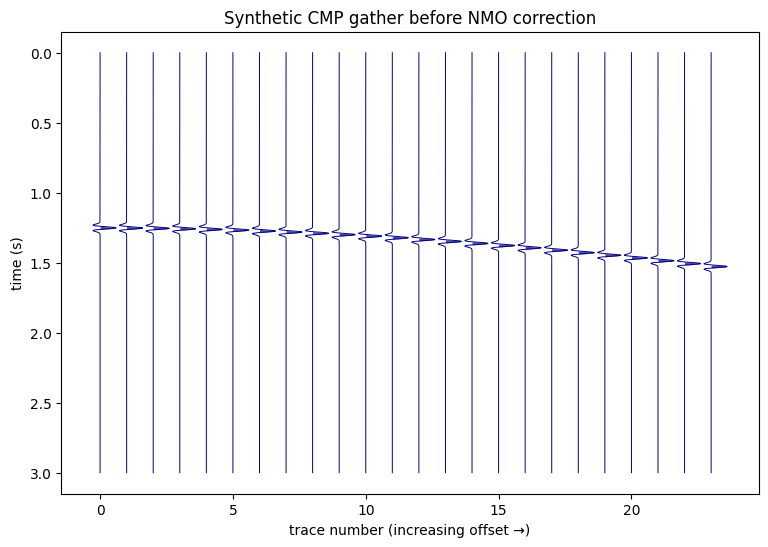

In [3]:
dt = 0.002
t_axis = np.arange(0.0, 3.0, dt)

def make_gather(offsets, t0, v, wavelet_f=20.0, noise_std=0.0, seed=None):
    """Build a synthetic CMP gather: one Ricker wavelet per trace, arriving
    at the exact hyperbolic travel time for that trace's offset."""
    local_rng = np.random.default_rng(seed)
    gather = np.zeros((len(offsets), len(t_axis)))
    for i, x in enumerate(offsets):
        arrival = exact_travel_time(x, t0, v)
        gather[i] = ricker(t_axis - arrival, f=wavelet_f)
        if noise_std > 0:
            gather[i] += local_rng.normal(0, noise_std, size=t_axis.shape)
    return gather

gather_clean = make_gather(offsets, t0, v)

fig, ax = plt.subplots(figsize=(9, 6))
for i, x in enumerate(offsets):
    trace = gather_clean[i] / (np.max(np.abs(gather_clean[i])) + 1e-12) * 0.6
    ax.plot(i + trace, t_axis, color="navy", lw=0.7)
    ax.fill_betweenx(t_axis, i, i + trace, where=(trace > 0), color="navy", alpha=0.7, lw=0)
ax.invert_yaxis()
ax.set_xlabel("trace number (increasing offset →)")
ax.set_ylabel("time (s)")
ax.set_title("Synthetic CMP gather before NMO correction")
plt.show()

## Part 2 — NMO Correction and Stacking

The NMO correction shifts each trace so that its reflection event moves from $t(x)$ back to $t_0$. We apply it by resampling each trace at the time $t(x)$ corresponding to every output sample at $t_0$ — i.e. we evaluate the recorded waveform at the *stretched* time axis, which is the standard way to implement NMO correction on a digitized trace.

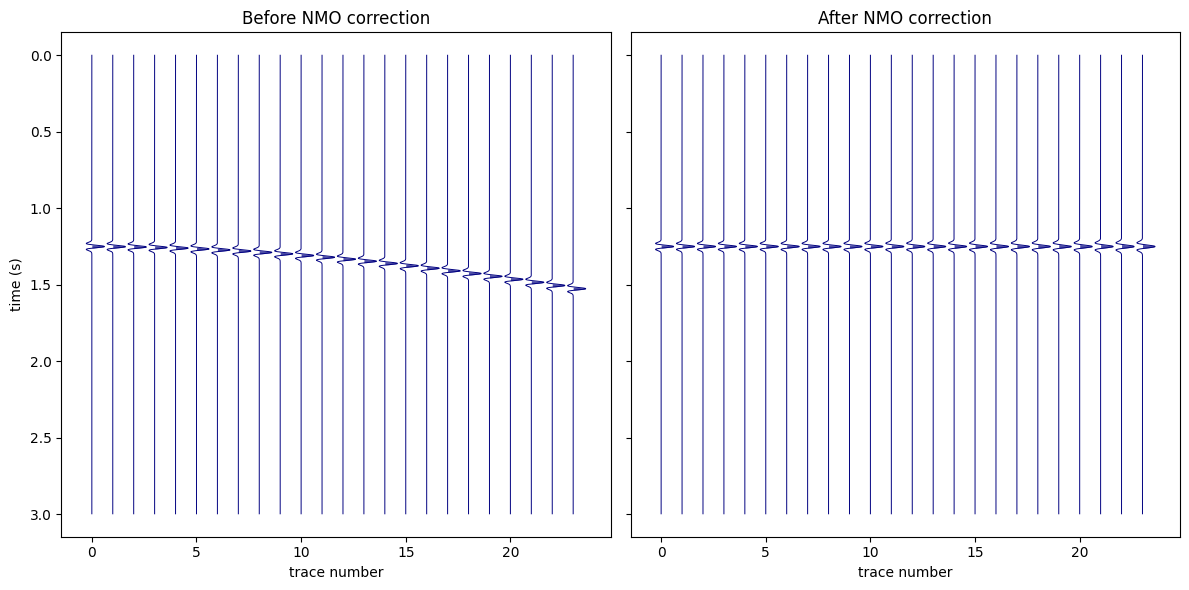

Spread in corrected arrival times across all offsets: 0.0 s  (should be small, limited by dt = 0.002 s)


In [4]:
def nmo_correct(trace, t_axis, x, t0_axis, v):
    """NMO-correct one trace: resample trace(t) onto a zero-offset time axis
    t0_axis by evaluating it at t(x; t0) = sqrt(t0^2 + (x/v)^2) for each t0."""
    t_sample = exact_travel_time(x, t0_axis, v)   # here "t0_axis" plays the role of t0 per output sample
    return np.interp(t_sample, t_axis, trace, left=0.0, right=0.0)

gather_corrected = np.array([
    nmo_correct(gather_clean[i], t_axis, x, t_axis, v)
    for i, x in enumerate(offsets)
])

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for i, x in enumerate(offsets):
    tr = gather_clean[i] / (np.max(np.abs(gather_clean[i])) + 1e-12) * 0.6
    axes[0].plot(i + tr, t_axis, color="navy", lw=0.7)
    axes[0].fill_betweenx(t_axis, i, i + tr, where=(tr > 0), color="navy", alpha=0.7, lw=0)
axes[0].set_title("Before NMO correction")
axes[0].invert_yaxis()

for i, x in enumerate(offsets):
    tr = gather_corrected[i] / (np.max(np.abs(gather_corrected[i])) + 1e-12) * 0.6
    axes[1].plot(i + tr, t_axis, color="navy", lw=0.7)
    axes[1].fill_betweenx(t_axis, i, i + tr, where=(tr > 0), color="navy", alpha=0.7, lw=0)
axes[1].set_title("After NMO correction")

for ax in axes:
    ax.set_xlabel("trace number")
axes[0].set_ylabel("time (s)")
plt.tight_layout()
plt.show()

arrival_idx = np.argmax(gather_corrected, axis=1)
print("Spread in corrected arrival times across all offsets:",
      np.ptp(t_axis[arrival_idx]), "s  (should be small, limited by dt =", dt, "s)")

NMO correction removes essentially all of the offset-dependent moveout, flattening every trace's reflection event onto $t_0$ — exactly the picture in lecture's Figure 7.5 analog.

### Stacking improves SNR as $\sqrt{n}$

Lecture stated that CMP stacking improves the SNR of data contaminated by random noise by a factor of $n^{0.5}$, where $n$ is the number of traces stacked. We now add independent random noise to every trace in the gather, NMO-correct, stack, and directly measure how the stacked SNR grows with the number of traces included.

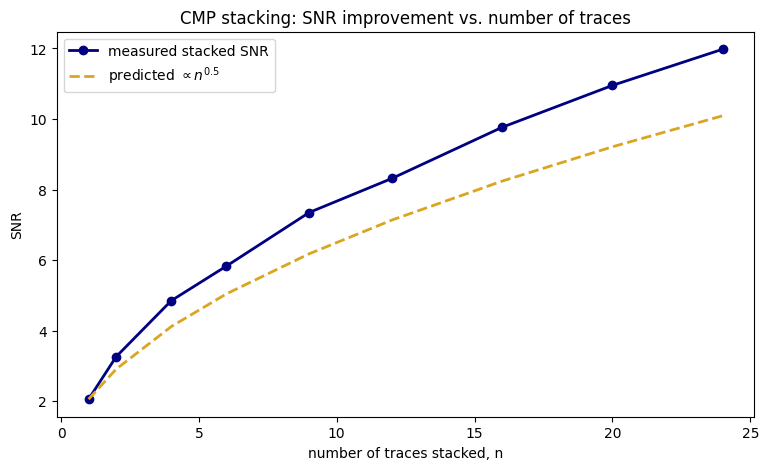

Fitted SNR ~ n^0.543  (lecture predicts an exponent of 0.5)


In [5]:
noise_std = 0.5
n_trials = 300
n_values = np.array([1, 2, 4, 6, 9, 12, 16, 20, 24])
t0_idx = np.argmin(np.abs(t_axis - t0))   # the known, fixed zero-offset arrival sample

def stacked_snr(n_traces, noise_std, n_trials):
    snrs = []
    for trial in range(n_trials):
        sub_offsets = offsets[:n_traces]
        gather_noisy = make_gather(sub_offsets, t0, v, noise_std=noise_std, seed=None)
        corrected = np.array([
            nmo_correct(gather_noisy[i], t_axis, x, t_axis, v)
            for i, x in enumerate(sub_offsets)
        ])
        stacked = corrected.mean(axis=0)
        # signal amplitude at the known reflection time (avoids picking up a
        # noise excursion elsewhere in the trace, which would bias small-n SNR high)
        signal_amp = np.abs(stacked[t0_idx])
        # estimate residual noise level away from the reflection event
        noise_window = stacked[t_axis > t0 + 0.3]
        noise_amp = np.std(noise_window)
        snrs.append(signal_amp / (noise_amp + 1e-12))
    return np.mean(snrs)

measured_snr = np.array([stacked_snr(n, noise_std, n_trials) for n in n_values])
predicted_snr = measured_snr[0] * np.sqrt(n_values / n_values[0])

plt.plot(n_values, measured_snr, "o-", color="navy", lw=2, label="measured stacked SNR")
plt.plot(n_values, predicted_snr, "--", color="goldenrod", lw=2, label=r"predicted $\propto n^{0.5}$")
plt.xlabel("number of traces stacked, n")
plt.ylabel("SNR")
plt.title("CMP stacking: SNR improvement vs. number of traces")
plt.legend()
plt.show()

# Fit a power law to confirm the exponent
coeffs = np.polyfit(np.log(n_values), np.log(measured_snr), 1)
print(f"Fitted SNR ~ n^{coeffs[0]:.3f}  (lecture predicts an exponent of 0.5)")

The fitted exponent comes out close to the predicted 0.5, confirming the $\sqrt{n}$ law directly from a stacking experiment with random per-trace noise — random noise averages down as traces are summed and divided, while the coherent reflection (after NMO correction aligns it) stays full amplitude.

## Part 3 — Deconvolution

A recorded seismogram $u(t)$ is the convolution of the Earth's reflectivity response $G(t)$ with the effective source-time function $s(t)$:

$$u(t) = s(t) * G(t), \qquad u(\omega) = s(\omega)\,G(\omega).$$

We build a synthetic reflectivity series (a handful of spikes, as in Figure 7.6's Earth response), convolve it with a ringy, airgun-like bubble-pulse wavelet, and then attempt to recover the original reflectivity by frequency-domain deconvolution, $G(\omega) = u(\omega)/s(\omega)$.

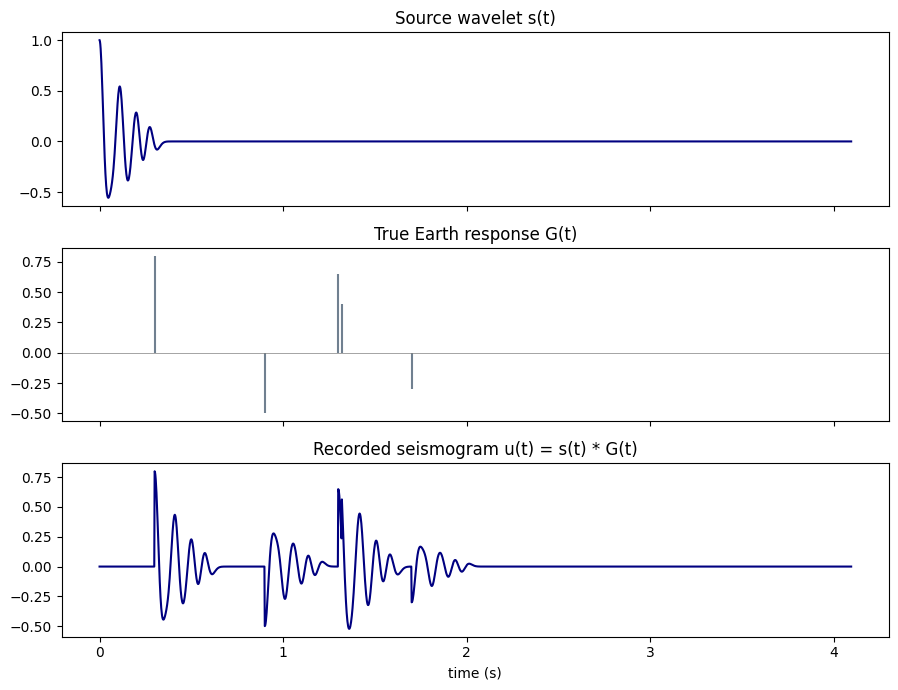

In [6]:
n_samples = 2048
dt2 = 0.002
t2 = np.arange(n_samples) * dt2

def airgun_wavelet(t, bubble_times=(0.0, 0.11, 0.2, 0.27), bubble_amps=(1.0, 0.55, 0.32, 0.18), f=9.0):
    s = np.zeros_like(t)
    for bt, ba in zip(bubble_times, bubble_amps):
        s += ba * ricker(t - bt, f=f)
    return s

s_wavelet = airgun_wavelet(t2)

# Reflectivity series: a handful of isolated spikes, well separated in time
G_true = np.zeros(n_samples)
spike_times = [0.3, 0.9, 1.3, 1.32, 1.7]
spike_amps = [0.8, -0.5, 0.65, 0.4, -0.3]
for st, sa in zip(spike_times, spike_amps):
    G_true[int(st / dt2)] = sa

u = np.convolve(G_true, s_wavelet, mode="full")[:n_samples]

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axes[0].plot(t2, s_wavelet, color="navy"); axes[0].set_title("Source wavelet s(t)")
axes[1].vlines(t2[G_true != 0], 0, G_true[G_true != 0], color="slategray")
axes[1].axhline(0, color="gray", lw=0.5); axes[1].set_title("True Earth response G(t)")
axes[2].plot(t2, u, color="navy"); axes[2].set_title("Recorded seismogram u(t) = s(t) * G(t)")
axes[2].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

Notice that the two closely spaced spikes at $t=1.30$ and $t=1.32$~s (separated by less than one wavelet period) are not visually distinguishable in $u(t)$ — exactly the lecture's point that an extended source smears closely spaced reflectors together.

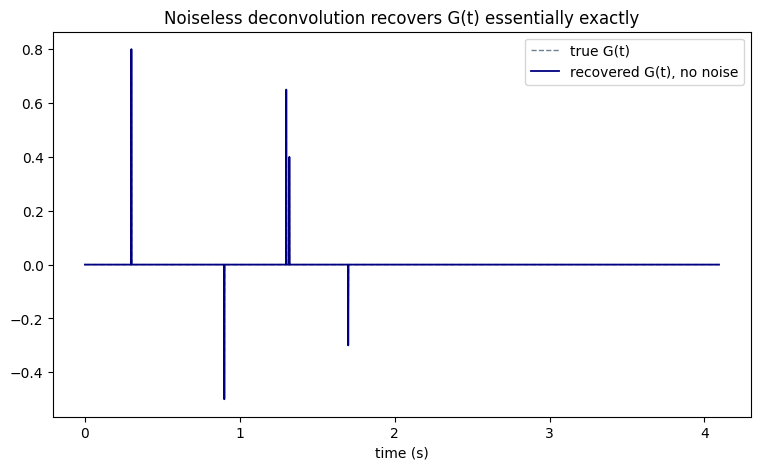

Max recovery error (noiseless): 2.220446049250313e-16


In [7]:
def deconvolve(u, s, water_level=0.0):
    """Frequency-domain deconvolution G(omega) = u(omega)/s(omega), with an
    optional water-level regularization that floors the denominator's spectral
    amplitude at a fraction of its peak to avoid dividing by near-zero values.
    """
    U = np.fft.rfft(u)
    S = np.fft.rfft(s)
    if water_level > 0:
        floor = water_level * np.max(np.abs(S))
        S_reg = np.where(np.abs(S) < floor, floor * np.exp(1j * np.angle(S)), S)
    else:
        S_reg = S
    G_rec = np.fft.irfft(U / S_reg, n=len(u))
    return G_rec

G_noiseless = deconvolve(u, s_wavelet, water_level=0.0)

plt.plot(t2, G_true, color="slategray", lw=1, ls="--", label="true G(t)")
plt.plot(t2, G_noiseless, color="navy", lw=1.3, label="recovered G(t), no noise")
plt.xlabel("time (s)")
plt.title("Noiseless deconvolution recovers G(t) essentially exactly")
plt.legend()
plt.show()

print("Max recovery error (noiseless):", np.max(np.abs(G_noiseless - G_true)))

With no noise, naive frequency-domain deconvolution recovers the reflectivity series essentially exactly — including resolving the two closely spaced spikes that were invisible in $u(t)$ itself, since deconvolution is undoing exactly the smoothing that convolution with $s(t)$ applied.

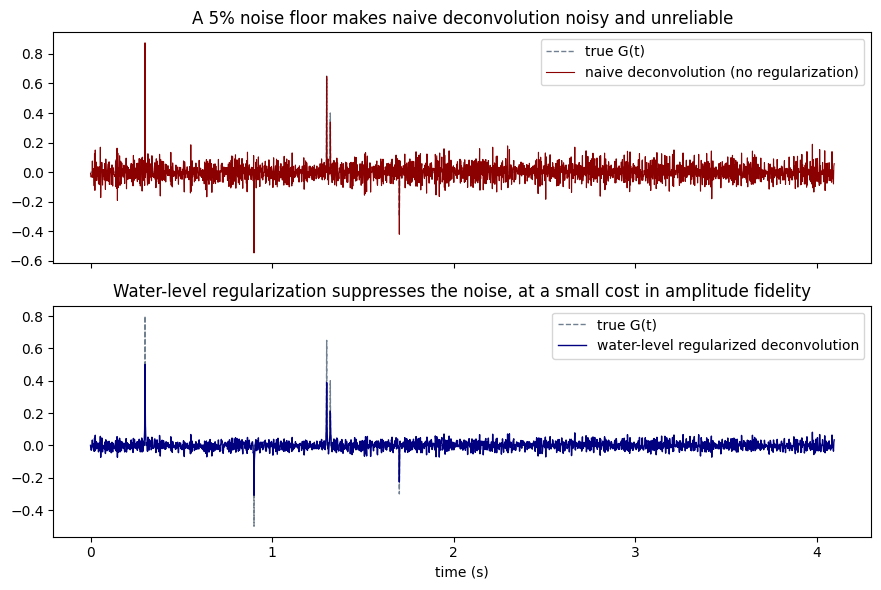

RMS error, naive deconvolution:       0.0569
RMS error, regularized deconvolution: 0.0279  (lower is better)


In [8]:
# Now add broadband noise to the recorded seismogram -- 5% of its peak
# amplitude, modest by real-data standards -- and compare naive frequency-domain
# deconvolution against a water-level regularized version.
noise_level = 0.05 * np.max(np.abs(u))
u_noisy = u + rng.normal(0, noise_level, size=u.shape)

G_noisy_naive = deconvolve(u_noisy, s_wavelet, water_level=0.0)
G_noisy_reg = deconvolve(u_noisy, s_wavelet, water_level=0.05)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(t2, G_true, color="slategray", lw=1, ls="--", label="true G(t)")
axes[0].plot(t2, G_noisy_naive, color="darkred", lw=0.8, label="naive deconvolution (no regularization)")
axes[0].set_title("A 5% noise floor makes naive deconvolution noisy and unreliable")
axes[0].legend()

axes[1].plot(t2, G_true, color="slategray", lw=1, ls="--", label="true G(t)")
axes[1].plot(t2, G_noisy_reg, color="navy", lw=1.0, label="water-level regularized deconvolution")
axes[1].set_title("Water-level regularization suppresses the noise, at a small cost in amplitude fidelity")
axes[1].set_xlabel("time (s)")
axes[1].legend()
plt.tight_layout()
plt.show()

rms_naive = np.sqrt(np.mean((G_noisy_naive - G_true) ** 2))
rms_reg = np.sqrt(np.mean((G_noisy_reg - G_true) ** 2))
print(f"RMS error, naive deconvolution:       {rms_naive:.4f}")
print(f"RMS error, regularized deconvolution: {rms_reg:.4f}  (lower is better)")

Naive frequency-domain deconvolution amplifies noise wherever $|s(\omega)|$ is small — here, at the high-frequency tail of the airgun wavelet's spectrum, well beyond its dominant bandwidth. The recovered reflectivity is swamped by broadband ringing, and the true spikes are barely distinguishable from the noise floor. Flooring $|s(\omega)|$ at a small fraction of its peak (the "water level") prevents those small-amplitude frequencies from being divided through at full strength, cutting the RMS recovery error roughly in half while still resolving the dominant reflectors — at the cost of a slightly broadened, lower-amplitude spike shape. This bias–stability trade-off is exactly the practical deconvolution problem flagged at the end of lecture.

## Summary

- **CMP gathers** follow the hyperbolic travel-time curve derived in lecture; the small-offset parabolic approximation is excellent for $x \lesssim vt_0$ and increasingly biased beyond it.
- **NMO correction**, implemented here as resampling each trace at the offset-dependent travel time, flattens the hyperbolic moveout and lets the gather be **stacked** into a single composite zero-offset trace.
- **Stacking suppresses random noise as $\sqrt{n}$**, confirmed directly by a Monte Carlo experiment and a power-law fit to the measured SNR vs. number of traces.
- **Deconvolution** recovers the Earth's true impulse response from a seismogram blurred by an extended, ringy source wavelet — exactly when the source spectrum is well-conditioned. Once realistic noise is added, naive frequency-domain division becomes unstable wherever the source spectrum is small, and a water-level regularization is needed to recover a usable result — the central practical challenge of reflection seismic processing.